# Market making on a lagging venue: Avellaneda-Stoikov against arbitrageurs

The Avellaneda & Stoikov (2008) model, replicated in [`avellaneda_stoikov.ipynb`](avellaneda_stoikov.ipynb), assumes that the market maker knows the fair price and that whoever trades against its quotes is **uninformed**. In real markets the price is discovered across several venues at once: in crypto, Binance usually leads and other venues, for example Hyperliquid, follow with a delay. A market maker quoting on the lagging venue sees the price late, and **arbitrageurs** who see the leading venue first pick off the quotes left behind.

We measured exactly this in the [Perpetual Alpha](https://github.com/lancellottimatteo19/perpetual-alpha) trading competition: 82% of the trades of the organisers' taker bot happened when the oracle had already moved ahead of the book, by 3.1 bp on average, and our market maker lost against it. Here the same mechanism is reproduced in a model with two venues, without the competition's oracle, to understand **how much the delay costs** and **which defences work**.

## The model

**Efficient price** (leading venue): a Brownian motion plus *information events*. At rate $\lambda_J$ a piece of news moves the price by $J \sim N(0, s_J^2)$, and the leading venue incorporates it gradually over $D$ seconds:
$$dP_t = \sigma\, dW_t + \text{events}.$$

**Market maker** on the lagging venue: it sees $P_{t-L}$, the price with a delay of $L$ seconds, and quotes with the Avellaneda-Stoikov formulas computed on that price:
$$r_t = P_{t-L} - q_t\, \gamma\, \sigma_{tot}^2 (T-t), \qquad \delta^a + \delta^b = \gamma\, \sigma_{tot}^2 (T-t) + \frac{2}{\gamma}\ln\left(1 + \frac{\gamma}{k}\right).$$

**Counterparties**
* *Noise traders*, uninformed: they look at our venue's book and fill a quote at distance $\delta$ from the mid with intensity $A e^{-k\delta}$, as in the paper.
* *Arbitrageurs*: they see the leading venue without delay, buy our ask when $P_t - \text{ask} > c$ and sell to our bid when $\text{bid} - P_t > c$, where $c$ is their cost (taker fees on both venues).

**Defences**
* *Wider spread*: a few extra basis points per side.
* *Guard*: if the price seen has moved by more than a threshold over the last second, the side the arbitrageurs would hit (the ask after a rise, the bid after a fall) is withdrawn for a short pause. It is a simplified version of the pause after the bot used in the competition.

| Parameter | Value |
|---|---|
| horizon, time step | 30 minutes, 100 ms |
| $\sigma$ | 0.5 bp per second$^{1/2}$ |
| events | one every 30 s, $s_J = 10$ bp, incorporated over $D = 3$ s |
| noise traders | $A = 0.5$ per second per side, $1/k = 1$ bp |
| arbitrageurs' cost $c$ | 3 bp |
| $\gamma$, maximum inventory | 0.05, 10 units |
| orders | 1 unit of an asset worth 100 USD; 200 paths |

The code is in [`two_venue_sim.py`](two_venue_sim.py), with tests in `tests/`. All variants run on the **same price paths**, so differences between strategies do not depend on chance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace

import two_venue_sim as tv

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.float_format', '{:.2f}'.format)

market = tv.Market()                    # half an hour, 100 ms step, the module's parameters
mm = tv.MarketMaker()                   # Avellaneda-Stoikov with gamma = 0.05 and a 1 s delay
N_PATHS = 200
price = tv.efficient_price(market, N_PATHS, np.random.default_rng(2026))

print(f"Avellaneda-Stoikov half-spread: {tv.as_half_spread(market, mm, market.horizon) / tv.BP:.2f} bp at the start, "
      f"{tv.as_half_spread(market, mm, 0) / tv.BP:.2f} bp at the end")
print(f"Volatility of the efficient price: {np.sqrt(market.total_variance * 86400) / market.s0:.1%} a day")

Avellaneda-Stoikov half-spread: 2.61 bp at the start, 1.00 bp at the end
Volatility of the efficient price: 5.6% a day


## 1. The textbook case and the realistic case

In [2]:
def run(mk=market, m=mm, **kw):
    return tv.simulate(mk, m, n_paths=N_PATHS, seed=7, price=price, **kw)

results = {
    'Textbook: no arbitrageurs, no delay': run(replace(market, arbitrage=False), replace(mm, latency=0.0)),
    'With arbitrageurs, 1 s delay': run(trace=True),
}
pd.DataFrame({k: tv.summary(r) for k, r in results.items()}).T

,PnL,PnL sd,edge,inventory,fees,noise fills,noise markout 10s (bp),arbitrage fills,arbitrage markout 10s (bp)
"Textbook: no arbitrageurs, no delay",4.47,0.70,4.43,0.04,0.00,440.51,1.01,0.00,NaN
"With arbitrageurs, 1 s delay",0.09,1.93,3.98,-3.89,0.00,476.17,1.91,68.11,-13.12


With no arbitrageurs and no delay, Avellaneda-Stoikov earns on average **4.47 USD per half hour**. Each fill against a noise trader is worth about +1 bp at 10 seconds: this is the spread captured.

With a **1 second delay** and arbitrageurs, the profit falls to **0.09 USD (−98%)**. Arbitrageurs account for only 68 fills out of about 540 (13%), but each one costs **−13 bp** at 10 seconds on average. The loss goes mostly through the **inventory** (−3.89 USD): an arbitrageur sells to us just before the price falls further, and we are left with the wrong position.

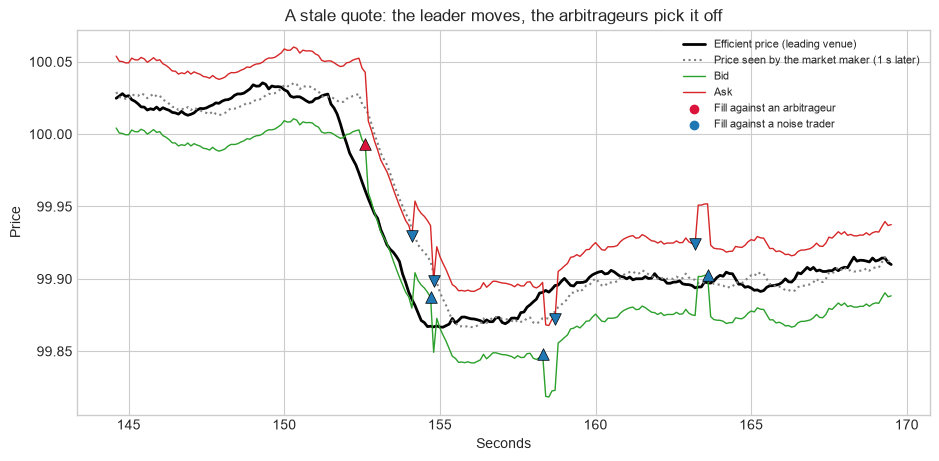

In [3]:
r = results['With arbitrageurs, 1 s delay']
tr, dt = r['trace'], market.dt
arb_times = [f[0] for f in tr['fills'] if f[2] == 'arbitrage']
t0 = max(arb_times[0] - 8, 0)
t = np.arange(market.steps) * dt
w = (t >= t0) & (t <= t0 + 25)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t[w], r['price'][:-1, 0][w], color='black', lw=2, label='Efficient price (leading venue)')
ax.plot(t[w], tr['seen'][w], color='gray', ls=':', label='Price seen by the market maker (1 s later)')
ax.plot(t[w], tr['bid'][w], color='tab:green', lw=1, label='Bid')
ax.plot(t[w], tr['ask'][w], color='tab:red', lw=1, label='Ask')
for when, px, who, side in tr['fills']:
    if t0 <= when <= t0 + 25:
        ax.scatter(when, px, marker='^' if side > 0 else 'v', s=70, zorder=5,
                   color='crimson' if who == 'arbitrage' else 'tab:blue', edgecolor='black', linewidth=0.5)
ax.scatter([], [], marker='o', color='crimson', label='Fill against an arbitrageur')
ax.scatter([], [], marker='o', color='tab:blue', label='Fill against a noise trader')
ax.set_title('A stale quote: the leader moves, the arbitrageurs pick it off')
ax.set_xlabel('Seconds'); ax.set_ylabel('Price')
ax.legend(loc='best', fontsize=8)
plt.show()

In the chart the leading venue falls by about 15 bp in three seconds. The market maker sees the move one second late, so for a moment its bid stays above the true price: an arbitrageur sells to us there (red triangle), and the price keeps falling.

The table and chart below show the difference between the two counterparties. Against noise traders the gain grows after the fill. Against arbitrageurs we are already 3.75 bp down at the fill, and the move that follows takes the loss to −13 bp: this is **adverse selection**.

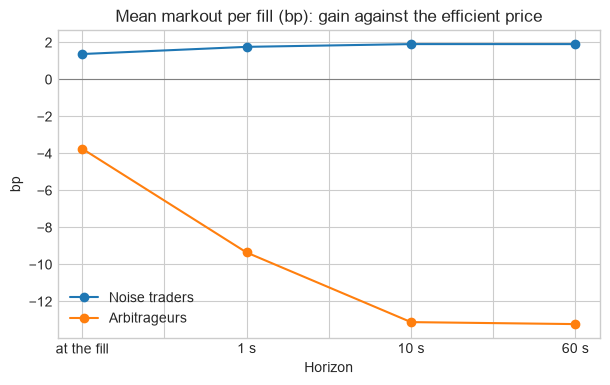

,at the fill,1 s,10 s,60 s
Noise traders,1.37,1.76,1.91,1.91
Arbitrageurs,-3.75,-9.35,-13.12,-13.22


In [4]:
horizons = (1.0, 10.0, 60.0)
mk = run(markout_horizons=horizons)
rows = {}
for who, name in [('noise', 'Noise traders'), ('arbitrage', 'Arbitrageurs')]:
    edge = mk['stats'][who]['edge'].sum() / mk['stats'][who]['fills'].sum() / tv.BP
    rows[name] = {'at the fill': edge, **{f'{h:g} s': tv.markout_bp(mk, who, h) for h in horizons}}
markout = pd.DataFrame(rows).T
ax = markout.T.plot(marker='o', figsize=(7, 4))
ax.axhline(0, color='gray', lw=0.8)
ax.set_title('Mean markout per fill (bp): gain against the efficient price')
ax.set_xlabel('Horizon'); ax.set_ylabel('bp')
plt.show()
markout

## 2. How much the delay costs

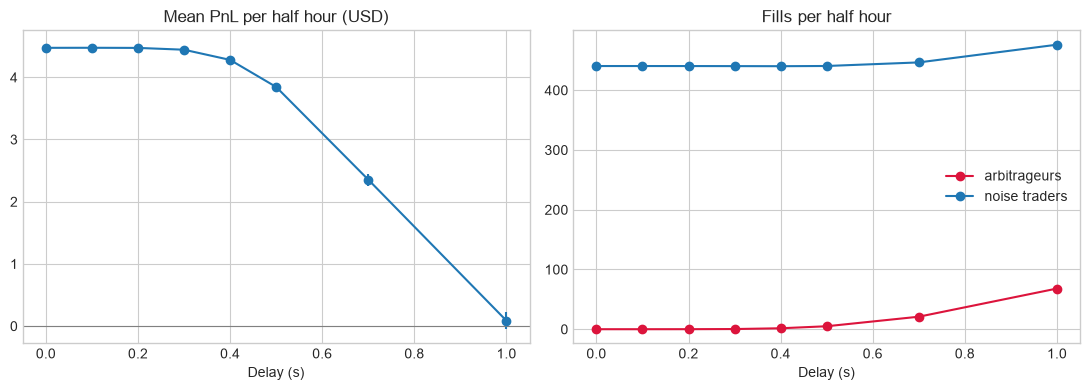

,PnL,PnL sd,edge,inventory,fees,noise fills,noise markout 10s (bp),arbitrage fills,arbitrage markout 10s (bp)
delay (s),,,,,,,,,
0.00,4.47,0.70,4.43,0.04,0.00,440.45,1.02,0.06,-1.50
0.10,4.47,0.70,4.43,0.04,0.00,440.46,1.02,0.06,-1.54
0.20,4.47,0.70,4.43,0.04,0.00,440.42,1.02,0.10,-8.65
0.30,4.44,0.70,4.42,0.02,0.00,440.32,1.02,0.34,-14.47
0.40,4.28,0.72,4.40,-0.12,0.00,440.19,1.04,1.63,-17.59
0.50,3.84,0.86,4.34,-0.49,0.00,440.54,1.07,5.01,-17.36
0.70,2.35,1.39,4.11,-1.76,0.00,446.51,1.25,20.98,-15.36
1.00,0.09,1.93,3.98,-3.89,0.00,476.17,1.91,68.11,-13.12


In [5]:
latencies = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]
lat = {L: tv.summary(run(m=replace(mm, latency=L))) for L in latencies}
lat = pd.DataFrame(lat).T
lat.index.name = 'delay (s)'

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(lat.index, lat['PnL'], yerr=lat['PnL sd'] / np.sqrt(N_PATHS), marker='o')
ax[0].axhline(0, color='gray', lw=0.8)
ax[0].set_title('Mean PnL per half hour (USD)'); ax[0].set_xlabel('Delay (s)')
ax[1].plot(lat.index, lat['arbitrage fills'], marker='o', color='crimson', label='arbitrageurs')
ax[1].plot(lat.index, lat['noise fills'], marker='o', color='tab:blue', label='noise traders')
ax[1].set_title('Fills per half hour'); ax[1].set_xlabel('Delay (s)'); ax[1].legend()
plt.tight_layout(); plt.show()
lat

Up to **300 ms** the delay costs practically nothing: the price does not have time to move beyond our half-spread plus the arbitrageurs' cost. From 400–500 ms the loss grows quickly, because fills against arbitrageurs increase.

We stop at 1 second because with longer delays the model becomes too optimistic. Noise traders look only at our book, so they would also fill stale quotes that favour us. On a real venue those fills would go to faster competing market makers.

## 3. Defences with a 1 second delay

**Widening the spread**

In [6]:
widen = {w: tv.summary(run(m=replace(mm, widen=w * tv.BP))) for w in [0.0, 0.5, 1.0, 2.0, 4.0]}
widen = pd.DataFrame(widen).T
widen.index.name = 'extra half-spread per side (bp)'
widen[['PnL', 'noise fills', 'arbitrage fills', 'arbitrage markout 10s (bp)']]

,PnL,noise fills,arbitrage fills,arbitrage markout 10s (bp)
extra half-spread per side (bp),,,,
0.00,0.09,476.17,68.11,-13.12
0.50,0.29,287.23,45.09,-13.94
1.00,0.15,174.25,30.77,-14.71
2.00,-0.14,63.77,14.66,-16.31
4.00,-0.15,7.95,3.37,-19.03


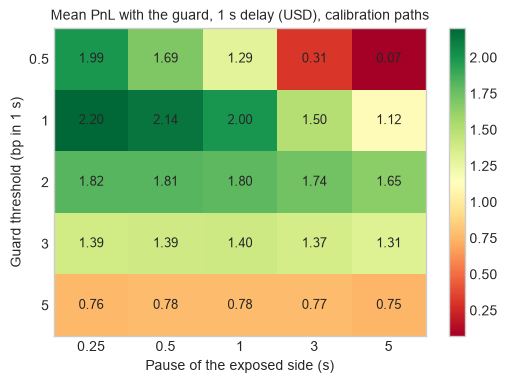

pause (s),0.25,0.50,1.00,3.00,5.00
threshold (bp in 1 s),,,,,
0.50,1.99,1.69,1.29,0.31,0.07
1.00,2.20,2.14,2.00,1.50,1.12
2.00,1.82,1.81,1.80,1.74,1.65
3.00,1.39,1.39,1.40,1.37,1.31
5.00,0.76,0.78,0.78,0.77,0.75


In [7]:
# threshold and pause are chosen on paths DIFFERENT from those on which the final result is evaluated
price_cal = tv.efficient_price(market, N_PATHS, np.random.default_rng(1))
thresholds, pauses = [0.5, 1.0, 2.0, 3.0, 5.0], [0.25, 0.5, 1.0, 3.0, 5.0]
grid = pd.DataFrame(index=pd.Index(thresholds, name='threshold (bp in 1 s)'), columns=pd.Index(pauses, name='pause (s)'), dtype=float)
for th in thresholds:
    for pa in pauses:
        grid.loc[th, pa] = tv.simulate(market, replace(mm, guard_bps=th, guard_pause=pa), n_paths=N_PATHS, seed=11, price=price_cal)['pnl'].mean()

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid.values, cmap='RdYlGn', aspect='auto')
ax.set_xticks(range(len(pauses)), [f'{p:g}' for p in pauses]); ax.set_yticks(range(len(thresholds)), [f'{t:g}' for t in thresholds])
ax.set_xlabel('Pause of the exposed side (s)'); ax.set_ylabel('Guard threshold (bp in 1 s)')
for i in range(len(thresholds)):
    for j in range(len(pauses)):
        ax.text(j, i, f'{grid.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.grid(False)
ax.set_title('Mean PnL with the guard, 1 s delay (USD), calibration paths', fontsize=10)
plt.colorbar(im); plt.show()
grid

**Widening the spread helps little.** The best PnL, with +0.5 bp per side, is 0.29 USD. A wider spread mainly drives away the noise traders, who are the source of the profit. Arbitrageurs keep hitting on large moves, and each of their fills costs even more: the markout goes from −13 to −19 bp.

**The guard works better.** It withdraws only the exposed side, and only when needed, so it removes the arbitrageurs' best opportunities without losing the noise traders' flow. Threshold and pause are chosen on a **separate set of paths** and evaluated in the final table on the main paths, so the result is not inflated by a choice made on the same data.

## 4. Final comparison

In [8]:
best_th, best_pa = np.unravel_index(np.nanargmax(grid.values), grid.shape)
guard = dict(guard_bps=thresholds[best_th], guard_pause=pauses[best_pa])
final = {
    'Textbook (no arbitrageurs)': run(replace(market, arbitrage=False), replace(mm, latency=0.0)),
    '1 s delay': run(),
    '1 s delay + 1 bp wider spread': run(m=replace(mm, widen=1.0 * tv.BP)),
    f"1 s delay + guard ({guard['guard_bps']:g} bp, {guard['guard_pause']:g} s)": run(m=replace(mm, **guard)),
    '200 ms delay': run(m=replace(mm, latency=0.2)),
    '200 ms delay + guard': run(m=replace(mm, latency=0.2, **guard)),
}
pd.DataFrame({k: tv.summary(v) for k, v in final.items()}).T

,PnL,PnL sd,edge,inventory,fees,noise fills,noise markout 10s (bp),arbitrage fills,arbitrage markout 10s (bp)
Textbook (no arbitrageurs),4.47,0.70,4.43,0.04,0.00,440.51,1.01,0.00,NaN
1 s delay,0.09,1.93,3.98,-3.89,0.00,476.17,1.91,68.11,-13.12
1 s delay + 1 bp wider spread,0.15,1.68,2.84,-2.68,0.00,174.25,2.74,30.77,-14.71
"1 s delay + guard (1 bp, 0.25 s)",2.10,1.22,4.11,-2.01,0.00,413.67,1.52,24.62,-16.89
200 ms delay,4.47,0.70,4.43,0.04,0.00,440.42,1.02,0.10,-8.65
200 ms delay + guard,4.66,0.74,4.14,0.52,0.00,403.26,1.16,0.11,-2.92


## Conclusions

| | PnL per half hour (USD) |
|---|---:|
| Textbook, no arbitrageurs | 4.47 |
| 1 s delay | 0.09 |
| 1 s + 1 bp wider spread | 0.15 |
| 1 s + guard (1 bp, 0.25 s) | 2.10 |
| 200 ms delay | 4.47 |

1. **A market maker's main risk is not the inventory itself but who it trades with.** Arbitrageurs are few, but each costs about seven times what a fill against a noise trader earns (−13 bp versus +1.9 bp at 10 seconds).
2. **Speed is the most effective defence.** With a 200 ms delay, in this model, adverse selection disappears. This is why professional market makers invest in infrastructure close to the exchange.
3. **Without speed, reacting the right way matters.** With a 1 second delay the guard recovers almost half of the lost profit. Widening the spread symmetrically barely helps.

These are the same conclusions as in the competition: in Perpetual Alpha the decisive defence was the pause after the bot, while cutting latency from 2 s to 100 ms without the pause reduced the loss without eliminating it.

**Limitations of the model.** Arbitrageurs have unlimited liquidity and react instantly. The queue of the book and other market makers are not modelled. Orders are for a single unit and the parameters are not estimated from real data: [`hyperliquid_binance_data.ipynb`](hyperliquid_binance_data.ipynb) calibrates them on recorded Binance and Hyperliquid data.

## Where this sits in the literature

The model is not a new idea: it combines three known strands in a form that is simple to simulate.

* **Adverse selection and the spread.** In Glosten and Milgrom (1985) the spread exists because part of the flow is informed, and the market maker recovers from uninformed traders what it loses to informed ones: this is the split between noise traders and arbitrageurs. Copeland and Galai (1983) describe a resting quote as a free option offered to the market; a stale quote is an option already in the money. Kyle (1985) is the classic model of the informed trader.
* **Optimal market making.** Avellaneda and Stoikov (2008) and Guéant, Lehalle and Fernandez-Tapia (2013) give optimal quotes under inventory risk. Cartea, Jaimungal and Ricci (2014) and Cartea, Jaimungal and Penalva (2015) add adverse selection and the tendency of the price to keep moving in the direction of informed orders: the rigorous optimal-control version of what the guard does here.
* **Latency and stale quotes.** This is the closest strand. In Budish, Cramton and Shim (2015), when a public signal moves the price, the fastest traders race to pick off stale quotes (*sniping*), and the cost falls on liquidity providers; this notebook is a simplified version in which the market maker always loses the race. Aquilina, Budish and O'Neill (2022) measure these races on London Stock Exchange data. Foucault, Kozhan and Tham (2017) show in the foreign exchange market that arbitrage opportunities created by information are toxic for liquidity providers. Menkveld (2013) studies a high-frequency market maker active on two venues.
* **Price discovery across venues.** Hasbrouck's (1995) *information share* measures how much of the price is formed on each venue, i.e. which one leads; Makarov and Schoar (2020) study arbitrage across crypto exchanges.
* **The same phenomenon in DeFi.** In the *loss-versus-rebalancing* of Milionis, Moallemi, Roughgarden and Zhang (2022), liquidity providers in an automated market maker lose to the arbitrageurs who realign its price with centralised exchanges: the extreme case of this model, in which quotes never update by themselves.
* **Measures and defences.** Markouts by counterparty are the standard measure of flow toxicity; the VPIN of Easley, López de Prado and O'Hara (2012) is a real-time version. Real defences resemble the guard: *last look* in foreign exchange and the asymmetric *speed bumps* of some exchanges, which delay takers to give market makers time to update their quotes.

The contribution of this notebook is not theoretical: it makes the Budish-Cramton-Shim mechanism measurable in a simulation starting from Avellaneda-Stoikov, and links it to what we observed in the Perpetual Alpha competition. The next step, taken in [`hyperliquid_binance_data.ipynb`](hyperliquid_binance_data.ipynb), is to estimate its parameters on data: how far Binance leads Hyperliquid and how toxic the flow is after a Binance move.

## References

* Aquilina, M., Budish, E. and O'Neill, P. (2022). Quantifying the high-frequency trading "arms race". *Quarterly Journal of Economics*.
* Avellaneda, M. and Stoikov, S. (2008). High-frequency trading in a limit order book. *Quantitative Finance*.
* Budish, E., Cramton, P. and Shim, J. (2015). The high-frequency trading arms race: frequent batch auctions as a market design response. *Quarterly Journal of Economics*.
* Cartea, Á., Jaimungal, S. and Penalva, J. (2015). *Algorithmic and High-Frequency Trading*. Cambridge University Press.
* Cartea, Á., Jaimungal, S. and Ricci, J. (2014). Buy low, sell high: a high frequency trading perspective. *SIAM Journal on Financial Mathematics*.
* Copeland, T. and Galai, D. (1983). Information effects on the bid-ask spread. *Journal of Finance*.
* Easley, D., López de Prado, M. and O'Hara, M. (2012). Flow toxicity and liquidity in a high-frequency world. *Review of Financial Studies*.
* Foucault, T., Kozhan, R. and Tham, W. W. (2017). Toxic arbitrage. *Review of Financial Studies*.
* Glosten, L. and Milgrom, P. (1985). Bid, ask and transaction prices in a specialist market with heterogeneously informed traders. *Journal of Financial Economics*.
* Guéant, O., Lehalle, C.-A. and Fernandez-Tapia, J. (2013). Dealing with the inventory risk: a solution to the market making problem. *Mathematics and Financial Economics*.
* Hasbrouck, J. (1995). One security, many markets: determining the contributions to price discovery. *Journal of Finance*.
* Kyle, A. S. (1985). Continuous auctions and insider trading. *Econometrica*.
* Makarov, I. and Schoar, A. (2020). Trading and arbitrage in cryptocurrency markets. *Journal of Financial Economics*.
* Menkveld, A. J. (2013). High frequency trading and the new market makers. *Journal of Financial Markets*.
* Milionis, J., Moallemi, C. C., Roughgarden, T. and Zhang, A. L. (2022). Automated market making and loss-versus-rebalancing. arXiv preprint.